# ResNet152V2 — Replicare Nawaz (toate cele 5 tier-uri)

**Strict Nawaz:**
- Architecture: ResNet152V2 + Dense(1024) + BN + Dropout + Dense(512) + BN + Dropout + Dense(7)
- Total params: 60,964,359 (match Table 4)
- Loss: sparse_categorical_crossentropy + class_weight (sklearn balanced)
- Optimizer: Adam, LR=1e-3
- Augmentation: flip + rotation ±20° + zoom ±10%
- Base trainable
- 30 epochs cu EarlyStopping(patience=10) pe val_accuracy
- ReduceLROnPlateau pe val_loss

**Pipeline tău:**
- TFRecord schema PASUL 4: `image_id, label, lesion_id, source, image_bytes`
- 3 TFRecords pe Drive: `val/`, `test/`, `tier5/` (= train_pool complet)
- Pentru tier1-4: filtrăm tier5 după lesion_id-urile din `step2/tier{N}_train.csv`
- Split lesion-level (fără data leakage)

## 1. Setup

In [34]:
from google.colab import drive
drive.mount('/content/drive')
print('Drive mounted')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Drive mounted


In [35]:
import os
import json
import time
import random
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    precision_recall_fscore_support,
)

# ─── REPRODUCIBILITY ───
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print(f'TF: {tf.__version__}')
print(f'GPU: {tf.config.list_physical_devices("GPU")}')
print(f'Seed: {SEED}')

TF: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Seed: 42


In [36]:
# ─── PATHS ───
DRIVE_BASE = Path('/content/drive/MyDrive/Thesis')
PIPELINE_DIR = DRIVE_BASE / 'pipeline_outputs'

TFRECORDS_DIR = PIPELINE_DIR / 'step4_tfrecords'   # val/, test/, tier5/
STEP2_DIR = PIPELINE_DIR / 'step2'                 # tier{N}_train.csv
OUTPUT_DIR = DRIVE_BASE / 'experiments' / 'resnet152v2_naive'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ─── HYPERPARAMETERS (strict Nawaz) ───
IMG_SIZE = 224
NUM_CLASSES = 7
BATCH_SIZE = 32
EPOCHS = 30
LEARNING_RATE = 1e-5   # ResNet152V2 cu 60M params — 1e-3 produce NaN la primul batch
DENSE1_UNITS = 1024
DENSE2_UNITS = 512
DROPOUT_RATE = 0.3
ROTATION_MAX_DEG = 20    # Nawaz spec
ZOOM_RANGE = 0.1

# Paper reference values (din Nawaz Table 4 + Table 5 raportare)
PAPER_TRAINABLE_PARAMS = 60_817_543
PAPER_ACCURACY = 91.0

# ─── TIERS TO RUN ───
# SMOKE TEST: setează TIERS_TO_RUN = [1] și EPOCHS = 5 pentru verificare rapidă (~20 min)
# Dacă val_loss e numeric (nu NaN) → restaurează TIERS_TO_RUN = [1,2,3,4,5] și EPOCHS = 30
TIERS_TO_RUN = [1, 2, 3, 4, 5]

# ─── LABELS ───
IDX_TO_LABEL = {0: 'akiec', 1: 'bcc', 2: 'bkl', 3: 'df', 4: 'mel', 5: 'nv', 6: 'vasc'}
CLASS_NAMES = [IDX_TO_LABEL[i] for i in range(NUM_CLASSES)]

print(f'TFRecords dir:  {TFRECORDS_DIR.exists()} {TFRECORDS_DIR}')
print(f'Step2 dir:      {STEP2_DIR.exists()} {STEP2_DIR}')
print(f'Output dir:     {OUTPUT_DIR}')
print(f'Tiers to run:   {TIERS_TO_RUN}')

for split in ['val', 'test', 'tier5']:
    d = TFRECORDS_DIR / split
    if d.exists():
        shards = sorted(d.glob('*.tfrecord'))
        print(f'  {split}: {len(shards)} shard-uri')
    else:
        print(f'  [WARNING] {split}/ nu există!')

TFRecords dir:  True /content/drive/MyDrive/Thesis/pipeline_outputs/step4_tfrecords
Step2 dir:      True /content/drive/MyDrive/Thesis/pipeline_outputs/step2
Output dir:     /content/drive/MyDrive/Thesis/experiments/resnet152v2_naive
Tiers to run:   [1, 2, 3, 4, 5]
  val: 3 shard-uri
  test: 3 shard-uri
  tier5: 21 shard-uri


## 2. Data pipeline

Schema TFRecord (PASUL 4): `image_id, label, lesion_id, source, image_bytes`.

In [37]:
FEATURE_DESC = {
    'image_id':    tf.io.FixedLenFeature([], tf.string),
    'label':       tf.io.FixedLenFeature([], tf.int64),
    'lesion_id':   tf.io.FixedLenFeature([], tf.string),
    'source':      tf.io.FixedLenFeature([], tf.string),
    'image_bytes': tf.io.FixedLenFeature([], tf.string),
}


def parse_example(example_proto):
    return tf.io.parse_single_example(example_proto, FEATURE_DESC)


def decode_image(parsed):
    img = tf.io.decode_jpeg(parsed['image_bytes'], channels=3)
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
    img = tf.cast(img, tf.float32) / 255.0   # [0, 1]
    return img, parsed['label'], parsed['lesion_id']


def get_split_files(split_name):
    pattern = str(TFRECORDS_DIR / split_name / '*.tfrecord')
    files = sorted(tf.io.gfile.glob(pattern))
    if not files:
        raise FileNotFoundError(f'No TFRecords found for split: {split_name}')
    return files


TRAIN_FILES = get_split_files('tier5')   # train pool complet (filter lesion_id pentru tier1-4)
VAL_FILES = get_split_files('val')
TEST_FILES = get_split_files('test')

print(f'Train pool (tier5): {len(TRAIN_FILES)} shards')
print(f'Val:                {len(VAL_FILES)} shards')
print(f'Test:               {len(TEST_FILES)} shards')

Train pool (tier5): 21 shards
Val:                3 shards
Test:               3 shards


In [38]:
# ─── Lesion ID filter pentru tier1-4 ───

def get_tier_lesion_ids(tier):
    """Returnează set de lesion_id-uri pentru tier_N (None pentru tier 5)."""
    if tier == 5:
        return None
    csv_path = STEP2_DIR / f'tier{tier}_train.csv'
    df = pd.read_csv(csv_path)
    return set(df['lesion_id'].astype(str).tolist())


def make_lesion_filter(allowed_ids):
    """Hash-table lookup în-graph pentru filter rapid."""
    keys = tf.constant(sorted(list(allowed_ids)), dtype=tf.string)
    values = tf.ones(len(allowed_ids), dtype=tf.int32)
    table = tf.lookup.StaticHashTable(
        tf.lookup.KeyValueTensorInitializer(keys, values),
        default_value=0,
    )
    return table


# Sanity check pentru toate tier-urile
for t in TIERS_TO_RUN:
    ids = get_tier_lesion_ids(t)
    if ids is None:
        print(f'Tier {t}: no filter (full tier5)')
    else:
        print(f'Tier {t}: {len(ids):,} lesion_id-uri')

Tier 1: 5,987 lesion_id-uri
Tier 2: 7,276 lesion_id-uri
Tier 3: 8,565 lesion_id-uri
Tier 4: 9,855 lesion_id-uri
Tier 5: no filter (full tier5)


In [39]:
# ─── Augmentation strict Nawaz: flip + rotation ±20° + zoom ±10% ───

# ─── Augmentation pure tf.image + scipy (fără SeedGenerator → fără bug CUDA) ───
# Bug istoric: tf.keras.layers.RandomFlip/RandomRotation cauzează
# CUDA_ERROR_INVALID_HANDLE când SeedGenerator se inițializează înainte de GPU.
from scipy.ndimage import rotate as scipy_rotate

def _random_rotate_np(image_np, max_deg):
    """Rotație random pe CPU cu scipy."""
    import numpy as np
    angle = np.random.uniform(-max_deg, max_deg)
    return scipy_rotate(
        image_np, angle, reshape=False, order=1, mode='reflect',
    ).astype(np.float32)


def augment_image(image, rotation_deg=ROTATION_MAX_DEG, zoom=ZOOM_RANGE):
    """Augmentation: flip + rotation ±rotation_deg° + zoom ±zoom (per Nawaz spec)."""
    image = tf.image.random_flip_left_right(image)
    image = tf.image.random_flip_up_down(image)

    image = tf.numpy_function(
        func=lambda x: _random_rotate_np(x, rotation_deg),
        inp=[image], Tout=tf.float32,
    )
    image.set_shape([None, None, 3])

    zoom_factor = tf.random.uniform([], 1.0 - zoom, 1.0 + zoom)
    new_size = tf.cast(tf.cast(IMG_SIZE, tf.float32) / zoom_factor, tf.int32)
    image = tf.image.resize(image, [new_size, new_size])
    image = tf.image.resize_with_crop_or_pad(image, IMG_SIZE, IMG_SIZE)

    image = tf.clip_by_value(image, 0.0, 1.0)
    return image

# Preprocessing per-model: folosim funcția oficială Keras
def preprocess_for_model(img_01):
    """Input: float32 [0,1]. Apply ResNet152V2 preprocessing.

    resnet_v2.preprocess_input așteaptă input în [0, 255] și returnează [-1, 1].
    Aplicăm clip defensiv ca să prevenim NaN/inf prin pipeline-ul de augmentation.
    """
    img_255 = img_01 * 255.0
    img_255 = tf.clip_by_value(img_255, 0.0, 255.0)  # defensive clip
    return tf.keras.applications.resnet_v2.preprocess_input(img_255)

print('Augmentation + preprocessing definite')

Augmentation + preprocessing definite


In [40]:
# ─── Dataset builders ───

def build_train_ds(tier):
    """Train dataset cu .repeat() — filter pe lesion_id pentru tier1-4."""
    allowed_ids = get_tier_lesion_ids(tier)

    ds = tf.data.TFRecordDataset(TRAIN_FILES, num_parallel_reads=tf.data.AUTOTUNE)
    ds = ds.map(parse_example, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.map(decode_image, num_parallel_calls=tf.data.AUTOTUNE)

    # Filter pe lesion_id pentru tier1-4
    if allowed_ids is not None:
        table = make_lesion_filter(allowed_ids)
        ds = ds.filter(lambda img, lbl, lid: tf.equal(table.lookup(lid), 1))

    # Drop lesion_id
    ds = ds.map(lambda img, lbl, lid: (img, lbl), num_parallel_calls=tf.data.AUTOTUNE)

    # CRITICAL: .repeat() ÎNAINTE de shuffle ca să nu rămânem fără date la fitting
    ds = ds.repeat()
    ds = ds.shuffle(buffer_size=2000, seed=SEED, reshuffle_each_iteration=True)

    # Augment + preprocess
    ds = ds.map(
        lambda img, lbl: (augment_image(img), lbl),
        num_parallel_calls=tf.data.AUTOTUNE,
    )
    ds = ds.map(
        lambda img, lbl: (preprocess_for_model(img), lbl),
        num_parallel_calls=tf.data.AUTOTUNE,
    )
    ds = ds.batch(BATCH_SIZE, drop_remainder=True)
    ds = ds.prefetch(tf.data.AUTOTUNE)
    return ds


def build_eval_ds(files):
    """Val/test dataset — fără shuffle, fără repeat, fără augment."""
    ds = tf.data.TFRecordDataset(files, num_parallel_reads=tf.data.AUTOTUNE)
    ds = ds.map(parse_example, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.map(decode_image, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.map(lambda img, lbl, lid: (img, lbl), num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.map(
        lambda img, lbl: (preprocess_for_model(img), lbl),
        num_parallel_calls=tf.data.AUTOTUNE,
    )
    ds = ds.batch(BATCH_SIZE, drop_remainder=False)
    ds = ds.prefetch(tf.data.AUTOTUNE)
    return ds


print('Dataset builders definite')

Dataset builders definite


In [41]:
# ─── Numărăm sample-urile per tier (pentru class_weight + steps_per_epoch) ───

def count_tier_samples(tier):
    """Numără sample-uri și calculează distribuția pe clase pentru un tier."""
    allowed_ids = get_tier_lesion_ids(tier)

    ds = tf.data.TFRecordDataset(TRAIN_FILES, num_parallel_reads=tf.data.AUTOTUNE)
    ds = ds.map(parse_example, num_parallel_calls=tf.data.AUTOTUNE)

    if allowed_ids is not None:
        table = make_lesion_filter(allowed_ids)
        ds = ds.filter(lambda x: tf.equal(table.lookup(x['lesion_id']), 1))

    counter = Counter()
    for ex in ds:
        counter[int(ex['label'].numpy())] += 1
    return dict(counter)


TIER_DISTRIBUTIONS = {}
print('Counting samples per tier (asta poate dura ~1-2 min):')
for t in TIERS_TO_RUN:
    dist = count_tier_samples(t)
    TIER_DISTRIBUTIONS[t] = dist
    total = sum(dist.values())
    print(f'  Tier {t}: {total:>6,} samples — {{{", ".join(f"{IDX_TO_LABEL[k]}: {v}" for k, v in sorted(dist.items()))}}}')

# Val/test sample counts
val_count = sum(1 for _ in tf.data.TFRecordDataset(VAL_FILES))
test_count = sum(1 for _ in tf.data.TFRecordDataset(TEST_FILES))
print(f'\nVal:  {val_count:,} samples')
print(f'Test: {test_count:,} samples')

Counting samples per tier (asta poate dura ~1-2 min):
  Tier 1:  8,042 samples — {akiec: 268, bcc: 396, bkl: 888, df: 93, mel: 910, nv: 5378, vasc: 109}
  Tier 2: 10,996 samples — {akiec: 502, bcc: 929, bkl: 1177, df: 118, mel: 1600, nv: 6536, vasc: 134}
  Tier 3: 14,061 samples — {akiec: 720, bcc: 1495, bkl: 1504, df: 138, mel: 2296, nv: 7750, vasc: 158}
  Tier 4: 17,300 samples — {akiec: 946, bcc: 2077, bkl: 1836, df: 164, mel: 3062, nv: 9022, vasc: 193}
  Tier 5: 20,299 samples — {akiec: 1192, bcc: 2661, bkl: 2128, df: 184, mel: 3628, nv: 10297, vasc: 209}

Val:  2,519 samples
Test: 2,513 samples


In [42]:
# ─── Class weights pentru fiecare tier (sklearn balanced) ───

def compute_class_weights(distribution, cap=5.0):
    """sklearn 'balanced' cu cap la cap×.

    Cap=5.0 previne extreme pentru clasele rare (df, vasc) care altfel
    primesc 12-15× pondere și destabilizează antrenarea (NaN loss la
    primul backward, collapse la single-class pentru ResNet152V2).
    """
    total = sum(distribution.values())
    raw = {k: total / (NUM_CLASSES * v) for k, v in distribution.items()}
    return {k: min(v, cap) for k, v in raw.items()}


TIER_CLASS_WEIGHTS = {}
print('Class weights per tier (capped la 5.0):')
for t in TIERS_TO_RUN:
    cw = compute_class_weights(TIER_DISTRIBUTIONS[t])
    TIER_CLASS_WEIGHTS[t] = cw
    cw_str = ', '.join(f'{IDX_TO_LABEL[k]}: {v:.2f}' for k, v in sorted(cw.items()))
    print(f'  Tier {t}: {cw_str}')

Class weights per tier (capped la 5.0):
  Tier 1: akiec: 4.29, bcc: 2.90, bkl: 1.29, df: 5.00, mel: 1.26, nv: 0.21, vasc: 5.00
  Tier 2: akiec: 3.13, bcc: 1.69, bkl: 1.33, df: 5.00, mel: 0.98, nv: 0.24, vasc: 5.00
  Tier 3: akiec: 2.79, bcc: 1.34, bkl: 1.34, df: 5.00, mel: 0.87, nv: 0.26, vasc: 5.00
  Tier 4: akiec: 2.61, bcc: 1.19, bkl: 1.35, df: 5.00, mel: 0.81, nv: 0.27, vasc: 5.00
  Tier 5: akiec: 2.43, bcc: 1.09, bkl: 1.36, df: 5.00, mel: 0.80, nv: 0.28, vasc: 5.00


## 3. Model (strict Nawaz Table 3)

Architecture:
```
Input(224, 224, 3)
  → ResNet152V2 (5,919,312)
  → GlobalAveragePooling2D
  → Dense(1024, relu) (1,311,744)
  → BatchNormalization (4,096)
  → Dropout(0.3)
  → Dense(256, relu) (262,400)
  → BatchNormalization (1,024)
  → Dropout(0.3)
  → Dense(7, softmax) (1,799)
Total: 60,964,359
Trainable: 60,817,543
```

In [43]:
def build_resnet152v2():
    """Strict Nawaz Table 3 — Total 60,964,359 / Trainable 60,817,543 (paper)."""
    inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))

    base = tf.keras.applications.ResNet152V2( include_top=False, weights='imagenet', input_shape=(IMG_SIZE, IMG_SIZE, 3) )
    base.trainable = True

    for layer in base.layers:
        if isinstance(layer, tf.keras.layers.BatchNormalization):
            layer.trainable = False

    x = base(inputs, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)

    x = tf.keras.layers.Dense(DENSE1_UNITS, activation='relu')(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Dropout(DROPOUT_RATE)(x)

    x = tf.keras.layers.Dense(DENSE2_UNITS, activation='relu')(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Dropout(DROPOUT_RATE)(x)

    outputs = tf.keras.layers.Dense(NUM_CLASSES, activation='softmax')(x)
    model = tf.keras.Model(inputs, outputs, name='ResNet152V2')

    total = model.count_params()
    trainable = sum(tf.size(w).numpy() for w in model.trainable_weights)
    print(f'  Total params:     {total:>12,}')
    print(f'  Trainable params: {trainable:>12,}  (BN-uri din bază înghețate)')

    return model

_test_model = build_resnet152v2()
del _test_model
tf.keras.backend.clear_session()

  Total params:       60,964,359
  Trainable params:   60,673,799  (BN-uri din bază înghețate)


## 4. Training utilities

In [44]:
def get_callbacks(tier_dir):
    return [
        tf.keras.callbacks.ModelCheckpoint(
            filepath=str(tier_dir / 'best.keras'),
            monitor='val_accuracy', mode='max',
            save_best_only=True, verbose=1,
        ),
        tf.keras.callbacks.EarlyStopping(
            monitor='val_accuracy', mode='max',
            patience=10, restore_best_weights=True, verbose=1,
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss', factor=0.5,
            patience=3, min_lr=1e-7, verbose=1,
        ),
        tf.keras.callbacks.CSVLogger(
            filename=str(tier_dir / 'history.csv'), append=False,
        ),
    ]


print('Callbacks definite')

Callbacks definite


In [45]:
def evaluate_model(model, ds, label='test'):
    """Evaluate cu accuracy, precision, recall, F1, AUC, confusion matrix."""

    print(f'Evaluating on {label}...')
    y_true, y_pred, y_proba = [], [], []
    for imgs, labels in ds:
        preds = model.predict(imgs, verbose=0)
        y_proba.extend(preds)
        y_pred.extend(np.argmax(preds, axis=1))
        y_true.extend(labels.numpy())

    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    y_proba = np.array(y_proba)

    acc = float(np.mean(y_true == y_pred))
    prec, rec, f1, _ = precision_recall_fscore_support( y_true, y_pred, average='weighted', zero_division=0, )
    macro_f1 = precision_recall_fscore_support( y_true, y_pred, average='macro', zero_division=0 )[2]

    try:
        auc = float(roc_auc_score(y_true, y_proba, multi_class='ovr', average='weighted'))
    except Exception:
        auc = float('nan')

    cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))
    report = classification_report( y_true, y_pred, target_names=CLASS_NAMES, zero_division=0 )

    print(f'  Accuracy:    {acc*100:.2f}%')
    print(f'  Precision:   {prec:.4f}')
    print(f'  Recall:      {rec:.4f}')
    print(f'  Weighted F1: {f1:.4f}')
    print(f'  Macro F1:    {macro_f1:.4f}')
    print(f'  AUC (ovr):   {auc:.4f}')

    return {
        'accuracy': acc,
        'precision': float(prec),
        'recall': float(rec),
        'weighted_f1': float(f1),
        'macro_f1': float(macro_f1),
        'auc': auc,
        'confusion_matrix': cm.tolist(),
        'classification_report': report,
    }

In [46]:
def plot_results(history, cm, tier, save_path):
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

    axes[0].plot(history.history['accuracy'], label='Train')
    axes[0].plot(history.history['val_accuracy'], label='Val')
    axes[0].set_title(f'Tier {tier} — Accuracy')
    axes[0].set_xlabel('Epoch')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(history.history['loss'], label='Train')
    axes[1].plot(history.history['val_loss'], label='Val')
    axes[1].set_title(f'Tier {tier} — Loss')
    axes[1].set_xlabel('Epoch')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    sns.heatmap( cm, annot=True, fmt='d', cmap='Blues', ax=axes[2], xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, cbar=False )
    axes[2].set_title(f'Tier {tier} — Confusion Matrix (test)')
    axes[2].set_xlabel('Predicted')
    axes[2].set_ylabel('True')

    plt.tight_layout()
    plt.savefig(save_path, dpi=120, bbox_inches='tight')
    plt.show()

In [47]:
def train_tier(tier):
    """Antrenează un tier. Returnează dict cu rezultatele."""
    tier_dir = OUTPUT_DIR / f'tier{tier}'
    tier_dir.mkdir(parents=True, exist_ok=True)

    results_path = tier_dir / 'results.json'
    if results_path.exists():
        print(f'\n   Tier {tier} already done, loading...')
        with open(results_path) as f:
            return json.load(f)

    print(f'\n{"#"*70}')
    print(f'# TIER {tier}')
    print(f'#   Output: {tier_dir}')
    print(f'#   Train samples: {sum(TIER_DISTRIBUTIONS[tier].values()):,}')
    print(f'#   LR={LEARNING_RATE}, batch={BATCH_SIZE}, epochs={EPOCHS}')
    print(f'{"#"*70}')

    start = time.time()
    tf.random.set_seed(SEED)
    np.random.seed(SEED)
    random.seed(SEED)

    train_ds = build_train_ds(tier)
    val_ds = build_eval_ds(VAL_FILES)
    test_ds = build_eval_ds(TEST_FILES)

    train_samples = sum(TIER_DISTRIBUTIONS[tier].values())
    steps_per_epoch = max(1, (train_samples // BATCH_SIZE) - 1)
    print(f'  Steps per epoch: {steps_per_epoch}')

    model = build_resnet152v2()
    print(f'  WARMUP: 10 epochs, head only, LR=1e-3...')

    model.layers[1].trainable = False
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4, clipnorm=1.0),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy'],
    )
    warmup_history = model.fit(
        train_ds,
        epochs=10,
        steps_per_epoch=steps_per_epoch,
        validation_data=val_ds,
        class_weight=TIER_CLASS_WEIGHTS[tier],
        verbose=1,
    )

    print(f'  MAIN: full unfreeze, LR={LEARNING_RATE}...')
    model.layers[1].trainable = True
    for layer in model.layers[1].layers:
        if isinstance(layer, tf.keras.layers.BatchNormalization):
            layer.trainable = False

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE, clipnorm=1.0),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy'],
    )

    history = model.fit(
        train_ds,
        epochs=EPOCHS,
        steps_per_epoch=steps_per_epoch,
        validation_data=val_ds,
        class_weight=TIER_CLASS_WEIGHTS[tier],
        callbacks=get_callbacks(tier_dir),
        verbose=1,
    )

    val_metrics = evaluate_model(model, val_ds, label=f'tier{tier}_val')
    test_metrics = evaluate_model(model, test_ds, label=f'tier{tier}_test')
    plot_results( history, np.array(test_metrics['confusion_matrix']), tier, save_path=tier_dir / 'plots.png' )

    elapsed_min = (time.time() - start) / 60

    results = {
        'tier': tier,
        'train_samples': train_samples,
        'epochs_run': len(history.history['loss']),
        'time_minutes': elapsed_min,
        'val': val_metrics,
        'test': test_metrics,
        'paper_accuracy': PAPER_ACCURACY,
        'history': {k: [float(x) for x in v] for k, v in history.history.items()},
    }

    with open(results_path, 'w') as f:
        json.dump(results, f, indent=2, default=str)
    model.save(tier_dir / 'final.keras')

    print(f'\n  Tier {tier} done in {elapsed_min:.1f} min')
    print(f'  Test accuracy: {test_metrics["accuracy"]*100:.2f}%')

    del model, train_ds, val_ds, test_ds
    tf.keras.backend.clear_session()
    import gc
    gc.collect()

    return results

## 5. Run all tiers


######################################################################
# TIER 1
#   Output: /content/drive/MyDrive/Thesis/experiments/resnet152v2_naive/tier1
#   Train samples: 8,042
#   LR=1e-05, batch=32, epochs=30
######################################################################
  Steps per epoch: 250
  Total params:       60,964,359
  Trainable params:   60,673,799  (BN-uri din bază înghețate)
  WARMUP: 10 epochs, head only, LR=1e-3...
Epoch 1/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 64s 144ms/step - accuracy: 0.3125 - loss: 1.6596 - val_accuracy: 0.3478 - val_loss: 2.1335
Epoch 2/10
  2/250 ━━━━━━━━━━━━━━━━━━━━ 14s 58ms/step - accuracy: 0.3984 - loss: 1.2052

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


250/250 ━━━━━━━━━━━━━━━━━━━━ 21s 86ms/step - accuracy: 0.4125 - loss: 1.3895 - val_accuracy: 0.3355 - val_loss: 2.6085
Epoch 3/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 22s 86ms/step - accuracy: 0.4629 - loss: 1.2424 - val_accuracy: 0.3755 - val_loss: 2.4552
Epoch 4/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 21s 84ms/step - accuracy: 0.5011 - loss: 1.1434 - val_accuracy: 0.4077 - val_loss: 2.2400
Epoch 5/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 20s 80ms/step - accuracy: 0.5224 - loss: 1.0819 - val_accuracy: 0.4375 - val_loss: 2.2193
Epoch 6/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 20s 78ms/step - accuracy: 0.5412 - loss: 1.0368 - val_accuracy: 0.4466 - val_loss: 2.2206
Epoch 7/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 20s 79ms/step - accuracy: 0.5715 - loss: 0.9741 - val_accuracy: 0.4645 - val_loss: 2.1377
Epoch 8/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 20s 79ms/step - accuracy: 0.5776 - loss: 0.9532 - val_accuracy: 0.4458 - val_loss: 2.1741
Epoch 9/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 20s 79ms/step - accuracy: 0.6011 - loss: 0.9060 - val_accurac

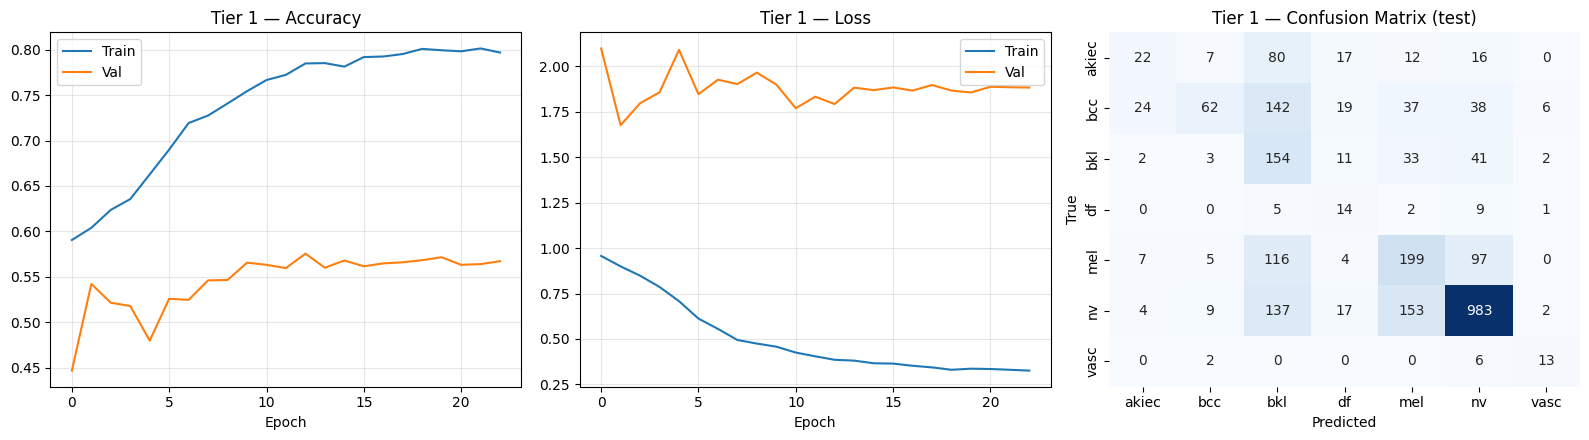


  Tier 1 done in 17.7 min
  Test accuracy: 57.58%

######################################################################
# TIER 2
#   Output: /content/drive/MyDrive/Thesis/experiments/resnet152v2_naive/tier2
#   Train samples: 10,996
#   LR=1e-05, batch=32, epochs=30
######################################################################
  Steps per epoch: 342
  Total params:       60,964,359
  Trainable params:   60,673,799  (BN-uri din bază înghețate)
  WARMUP: 10 epochs, head only, LR=1e-3...
Epoch 1/10
342/342 ━━━━━━━━━━━━━━━━━━━━ 69s 120ms/step - accuracy: 0.3524 - loss: 1.6196 - val_accuracy: 0.4478 - val_loss: 1.6940
Epoch 2/10
  3/342 ━━━━━━━━━━━━━━━━━━━━ 16s 49ms/step - accuracy: 0.4705 - loss: 1.0104

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


342/342 ━━━━━━━━━━━━━━━━━━━━ 27s 79ms/step - accuracy: 0.4547 - loss: 1.3711 - val_accuracy: 0.4756 - val_loss: 1.7187
Epoch 3/10
342/342 ━━━━━━━━━━━━━━━━━━━━ 27s 78ms/step - accuracy: 0.4837 - loss: 1.2319 - val_accuracy: 0.5161 - val_loss: 1.5643
Epoch 4/10
342/342 ━━━━━━━━━━━━━━━━━━━━ 26s 77ms/step - accuracy: 0.5265 - loss: 1.1550 - val_accuracy: 0.5411 - val_loss: 1.5021
Epoch 5/10
342/342 ━━━━━━━━━━━━━━━━━━━━ 25s 72ms/step - accuracy: 0.5377 - loss: 1.0912 - val_accuracy: 0.5288 - val_loss: 1.4915
Epoch 6/10
342/342 ━━━━━━━━━━━━━━━━━━━━ 25s 73ms/step - accuracy: 0.5575 - loss: 1.0593 - val_accuracy: 0.5312 - val_loss: 1.4367
Epoch 7/10
342/342 ━━━━━━━━━━━━━━━━━━━━ 25s 73ms/step - accuracy: 0.5634 - loss: 1.0298 - val_accuracy: 0.5367 - val_loss: 1.4640
Epoch 8/10
342/342 ━━━━━━━━━━━━━━━━━━━━ 25s 73ms/step - accuracy: 0.5779 - loss: 0.9787 - val_accuracy: 0.5609 - val_loss: 1.3711
Epoch 9/10
342/342 ━━━━━━━━━━━━━━━━━━━━ 25s 72ms/step - accuracy: 0.5970 - loss: 0.9409 - val_accurac

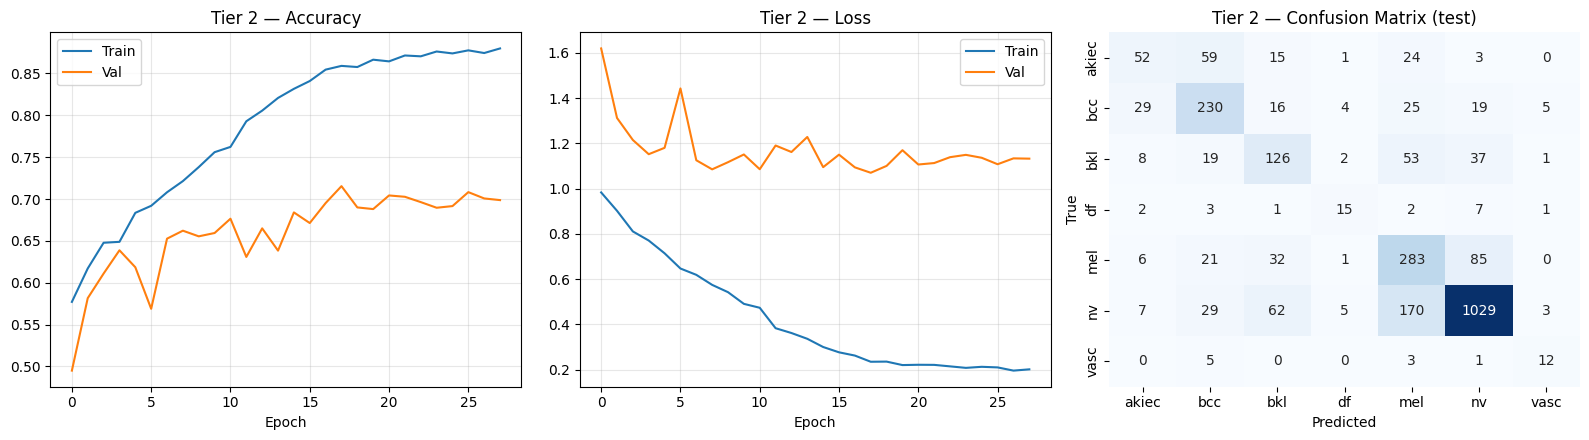


  Tier 2 done in 27.6 min
  Test accuracy: 69.52%

######################################################################
# TIER 3
#   Output: /content/drive/MyDrive/Thesis/experiments/resnet152v2_naive/tier3
#   Train samples: 14,061
#   LR=1e-05, batch=32, epochs=30
######################################################################
  Steps per epoch: 438
  Total params:       60,964,359
  Trainable params:   60,673,799  (BN-uri din bază înghețate)
  WARMUP: 10 epochs, head only, LR=1e-3...
Epoch 1/10
438/438 ━━━━━━━━━━━━━━━━━━━━ 76s 108ms/step - accuracy: 0.3629 - loss: 1.5928 - val_accuracy: 0.4843 - val_loss: 1.5602
Epoch 2/10
  3/438 ━━━━━━━━━━━━━━━━━━━━ 20s 48ms/step - accuracy: 0.4340 - loss: 2.0264

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


438/438 ━━━━━━━━━━━━━━━━━━━━ 33s 75ms/step - accuracy: 0.4569 - loss: 1.3425 - val_accuracy: 0.5014 - val_loss: 1.5428
Epoch 3/10
438/438 ━━━━━━━━━━━━━━━━━━━━ 33s 75ms/step - accuracy: 0.4972 - loss: 1.2225 - val_accuracy: 0.5347 - val_loss: 1.4618
Epoch 4/10
438/438 ━━━━━━━━━━━━━━━━━━━━ 33s 74ms/step - accuracy: 0.5141 - loss: 1.1545 - val_accuracy: 0.5379 - val_loss: 1.3970
Epoch 5/10
438/438 ━━━━━━━━━━━━━━━━━━━━ 31s 70ms/step - accuracy: 0.5347 - loss: 1.1119 - val_accuracy: 0.5558 - val_loss: 1.3478
Epoch 6/10
438/438 ━━━━━━━━━━━━━━━━━━━━ 31s 71ms/step - accuracy: 0.5557 - loss: 1.0334 - val_accuracy: 0.5566 - val_loss: 1.3067
Epoch 7/10
438/438 ━━━━━━━━━━━━━━━━━━━━ 31s 70ms/step - accuracy: 0.5678 - loss: 1.0155 - val_accuracy: 0.5550 - val_loss: 1.2931
Epoch 8/10
438/438 ━━━━━━━━━━━━━━━━━━━━ 31s 71ms/step - accuracy: 0.5828 - loss: 0.9585 - val_accuracy: 0.5748 - val_loss: 1.2436
Epoch 9/10
438/438 ━━━━━━━━━━━━━━━━━━━━ 31s 70ms/step - accuracy: 0.5987 - loss: 0.9508 - val_accurac

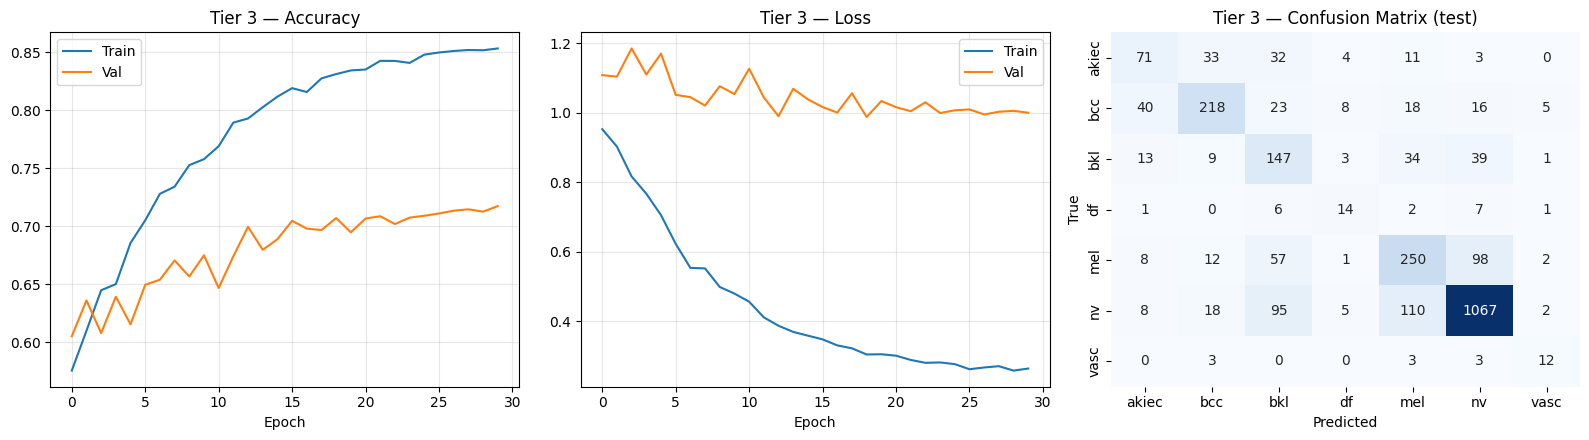


  Tier 3 done in 35.8 min
  Test accuracy: 70.79%

######################################################################
# TIER 4
#   Output: /content/drive/MyDrive/Thesis/experiments/resnet152v2_naive/tier4
#   Train samples: 17,300
#   LR=1e-05, batch=32, epochs=30
######################################################################
  Steps per epoch: 539
  Total params:       60,964,359
  Trainable params:   60,673,799  (BN-uri din bază înghețate)
  WARMUP: 10 epochs, head only, LR=1e-3...
Epoch 1/10
539/539 ━━━━━━━━━━━━━━━━━━━━ 92s 110ms/step - accuracy: 0.3851 - loss: 1.5628 - val_accuracy: 0.4657 - val_loss: 1.6934
Epoch 2/10
  2/539 ━━━━━━━━━━━━━━━━━━━━ 32s 60ms/step - accuracy: 0.3984 - loss: 1.6071

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


539/539 ━━━━━━━━━━━━━━━━━━━━ 42s 78ms/step - accuracy: 0.4668 - loss: 1.3326 - val_accuracy: 0.5181 - val_loss: 1.4441
Epoch 3/10
539/539 ━━━━━━━━━━━━━━━━━━━━ 42s 78ms/step - accuracy: 0.5038 - loss: 1.2121 - val_accuracy: 0.5697 - val_loss: 1.2969
Epoch 4/10
539/539 ━━━━━━━━━━━━━━━━━━━━ 42s 77ms/step - accuracy: 0.5202 - loss: 1.1457 - val_accuracy: 0.5570 - val_loss: 1.2925
Epoch 5/10
539/539 ━━━━━━━━━━━━━━━━━━━━ 40s 75ms/step - accuracy: 0.5421 - loss: 1.0802 - val_accuracy: 0.5788 - val_loss: 1.2113
Epoch 6/10
539/539 ━━━━━━━━━━━━━━━━━━━━ 40s 74ms/step - accuracy: 0.5520 - loss: 1.0378 - val_accuracy: 0.5518 - val_loss: 1.2743
Epoch 7/10
539/539 ━━━━━━━━━━━━━━━━━━━━ 40s 74ms/step - accuracy: 0.5748 - loss: 0.9793 - val_accuracy: 0.5800 - val_loss: 1.2097
Epoch 8/10
539/539 ━━━━━━━━━━━━━━━━━━━━ 40s 74ms/step - accuracy: 0.5832 - loss: 0.9747 - val_accuracy: 0.5709 - val_loss: 1.2046
Epoch 9/10
539/539 ━━━━━━━━━━━━━━━━━━━━ 40s 74ms/step - accuracy: 0.5894 - loss: 0.9392 - val_accurac

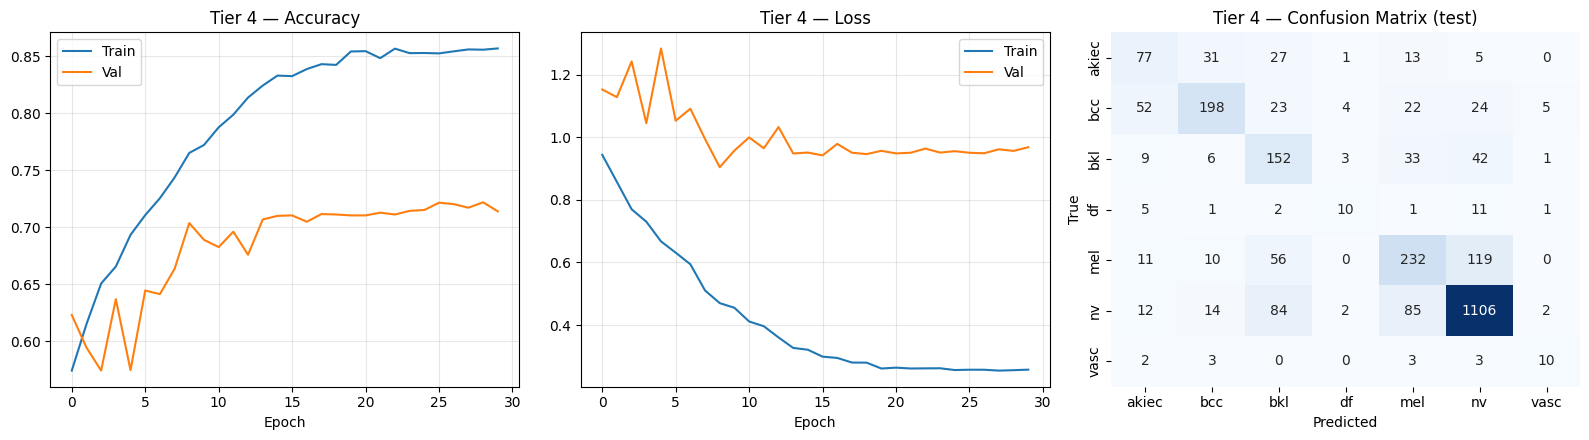


  Tier 4 done in 43.2 min
  Test accuracy: 71.03%

######################################################################
# TIER 5
#   Output: /content/drive/MyDrive/Thesis/experiments/resnet152v2_naive/tier5
#   Train samples: 20,299
#   LR=1e-05, batch=32, epochs=30
######################################################################
  Steps per epoch: 633
  Total params:       60,964,359
  Trainable params:   60,673,799  (BN-uri din bază înghețate)
  WARMUP: 10 epochs, head only, LR=1e-3...
Epoch 1/10
633/633 ━━━━━━━━━━━━━━━━━━━━ 99s 104ms/step - accuracy: 0.3897 - loss: 1.5472 - val_accuracy: 0.4934 - val_loss: 1.5032
Epoch 2/10
  2/633 ━━━━━━━━━━━━━━━━━━━━ 38s 60ms/step - accuracy: 0.3594 - loss: 1.4124

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


633/633 ━━━━━━━━━━━━━━━━━━━━ 49s 77ms/step - accuracy: 0.4687 - loss: 1.3051 - val_accuracy: 0.5316 - val_loss: 1.3779
Epoch 3/10
633/633 ━━━━━━━━━━━━━━━━━━━━ 48s 77ms/step - accuracy: 0.5069 - loss: 1.1916 - val_accuracy: 0.5498 - val_loss: 1.2714
Epoch 4/10
633/633 ━━━━━━━━━━━━━━━━━━━━ 48s 76ms/step - accuracy: 0.5266 - loss: 1.1354 - val_accuracy: 0.5522 - val_loss: 1.2555
Epoch 5/10
633/633 ━━━━━━━━━━━━━━━━━━━━ 46s 73ms/step - accuracy: 0.5477 - loss: 1.0675 - val_accuracy: 0.5836 - val_loss: 1.2068
Epoch 6/10
633/633 ━━━━━━━━━━━━━━━━━━━━ 47s 74ms/step - accuracy: 0.5544 - loss: 1.0361 - val_accuracy: 0.5744 - val_loss: 1.2035
Epoch 7/10
633/633 ━━━━━━━━━━━━━━━━━━━━ 47s 74ms/step - accuracy: 0.5684 - loss: 1.0025 - val_accuracy: 0.5748 - val_loss: 1.2277
Epoch 8/10
633/633 ━━━━━━━━━━━━━━━━━━━━ 47s 74ms/step - accuracy: 0.5741 - loss: 0.9603 - val_accuracy: 0.5903 - val_loss: 1.1797
Epoch 9/10
633/633 ━━━━━━━━━━━━━━━━━━━━ 81s 128ms/step - accuracy: 0.5896 - loss: 0.9373 - val_accura

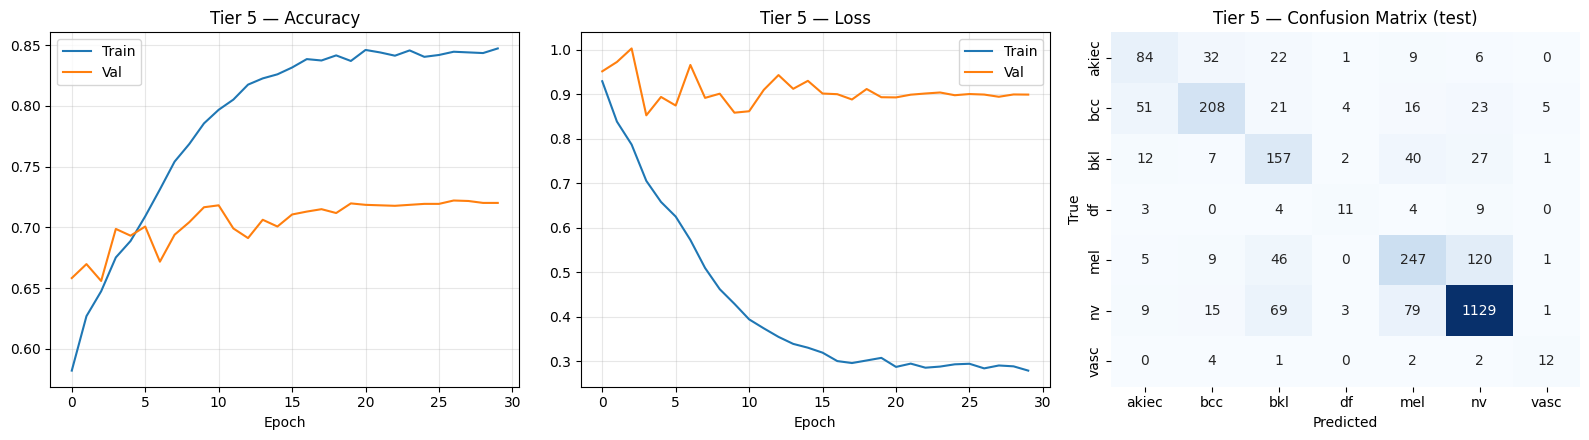


  Tier 5 done in 45.1 min
  Test accuracy: 73.54%

ALL TIERS COMPLETE


In [48]:
all_results = {}

for tier in TIERS_TO_RUN:
    all_results[tier] = train_tier(tier)

print('\n' + '=' * 70)
print('ALL TIERS COMPLETE')
print('=' * 70)

## 6. Summary

In [53]:
rows = []
for tier, res in sorted(all_results.items()):
    rows.append({
        'tier': tier,
        'train_samples': res['train_samples'],
        'epochs': res['epochs_run'],
        'val_acc': res['val']['accuracy'] * 100,
        'val_macro_f1': res['val']['macro_f1'],
        'test_acc': res['test']['accuracy'] * 100,
        'test_macro_f1': res['test']['macro_f1'],
        'test_weighted_f1': res['test']['weighted_f1'],
        'test_auc': res['test']['auc'],
        'time_min': res['time_minutes'],
    })

summary_df = pd.DataFrame(rows)
print(summary_df.to_string(index=False, float_format=lambda x: f'{x:.3f}'))

summary_df.to_csv(OUTPUT_DIR / 'summary.csv', index=False)
print(f'\nSummary saved to: {OUTPUT_DIR / "summary.csv"}')

 tier  train_samples  epochs  val_acc  val_macro_f1  test_acc  test_macro_f1  test_weighted_f1  test_auc  time_min
    1           8042      23   57.563         0.457    57.581          0.418             0.581     0.811    17.731
    2          10996      28   71.536         0.606    69.519          0.577             0.699     0.895    27.568
    3          14061      30   71.735         0.613    70.792          0.580             0.715     0.900    35.794
    4          17300      30   72.171         0.618    71.031          0.567             0.712     0.900    43.183
    5          20299      30   72.211         0.625    73.538          0.606             0.736     0.909    45.119

Summary saved to: /content/drive/MyDrive/Thesis/experiments/resnet152v2_naive/summary.csv


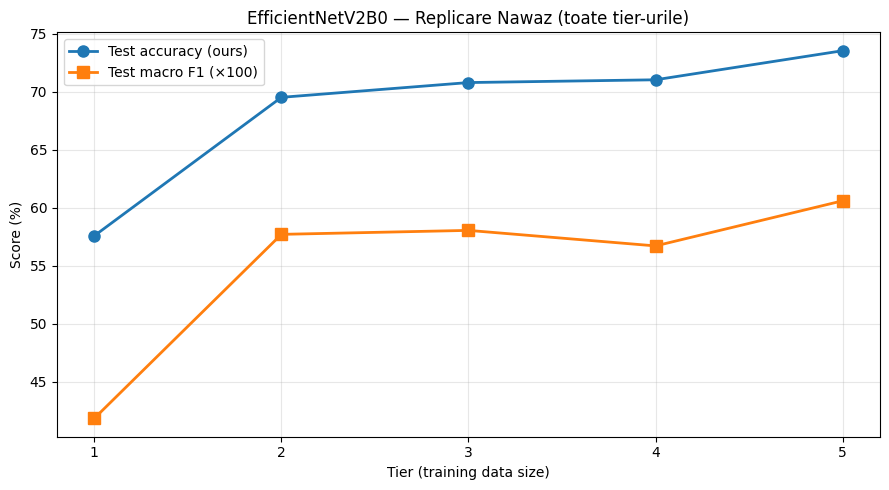

In [52]:
# ─── Test accuracy vs tier (cu paper baseline) ───
fig, ax = plt.subplots(figsize=(9, 5))

tiers_x = [r['tier'] for r in rows]
test_acc = [r['test_acc'] for r in rows]
macro_f1 = [r['test_macro_f1'] * 100 for r in rows]

ax.plot(tiers_x, test_acc, 'o-', label='Test accuracy (ours)', linewidth=2, markersize=8)
ax.plot(tiers_x, macro_f1, 's-', label='Test macro F1 (×100)', linewidth=2, markersize=8)
ax.set_xlabel('Tier (training data size)')
ax.set_ylabel('Score (%)')
ax.set_title('EfficientNetV2B0 — Replicare Nawaz (toate tier-urile)')
ax.set_xticks(tiers_x)
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'tiers_summary.png', dpi=120, bbox_inches='tight')
plt.show()

In [51]:
# ─── Classification report per tier (test set) ───
for tier in sorted(all_results.keys()):
    print(f'\n{"="*70}\nTier {tier} — TEST classification report\n{"="*70}')
    print(all_results[tier]['test']['classification_report'])


Tier 1 — TEST classification report
              precision    recall  f1-score   support

       akiec       0.37      0.14      0.21       154
         bcc       0.70      0.19      0.30       328
         bkl       0.24      0.63      0.35       246
          df       0.17      0.45      0.25        31
         mel       0.46      0.46      0.46       428
          nv       0.83      0.75      0.79      1305
        vasc       0.54      0.62      0.58        21

    accuracy                           0.58      2513
   macro avg       0.47      0.46      0.42      2513
weighted avg       0.65      0.58      0.58      2513


Tier 2 — TEST classification report
              precision    recall  f1-score   support

       akiec       0.50      0.34      0.40       154
         bcc       0.63      0.70      0.66       328
         bkl       0.50      0.51      0.51       246
          df       0.54      0.48      0.51        31
         mel       0.51      0.66      0.57       428
    